# Bulk ATAC-seq part 1: from reads to peaks

**Case study: How does chromatin accessibility in the liver change in a mouse model of diabetes and high-fat diet?**

Jeong BK, Choi WI, Choi W, et al. *A male mouse model for metabolic dysfunction-associated steatotic liver disease and hepatocellular carcinoma.* Nature Communications (2024) 15:6506. https://doi.org/10.1038/s41467-024-50660-y

**Research questions:**

1. How good are the ATAC-seq libraries, and how does their quality shape the results?
2. Which regions change accessibility in the livers of STZ + HFD mice, compared with control mice?
3. Which genes lie near these regions?

We answer the first question in this notebook and the other two in [part 2](part_2_consensus_peaks_macs_diff.ipynb) and [part 3](part_3_diffbind_deseq2.ipynb).

## Introduction

When transcription factors (TFs) and other proteins bind DNA, they displace nucleosomes and make the chromatin **accessible**. ATAC-seq (Assay for Transposase-Accessible Chromatin with sequencing) profiles these regions with the hyperactive **Tn5 transposase**: Tn5 cuts accessible DNA and inserts sequencing adapters in a single step ("tagmentation"). Each DNA fragment between two insertion sites is sequenced from both ends (paired-end).

Two properties of ATAC-seq data guide the whole analysis:

- **Fragment lengths are not random.** Short fragments (< 100 bp) come from nucleosome-free DNA, often where TFs bind. Longer fragments of ~200, ~400, ~600 bp span one, two or three nucleosomes. A good library shows this *nucleosome ladder*.
- **Signal concentrates at regulatory elements**: promoters (around transcription start sites, TSSs) and enhancers. A good library has much more signal at TSSs than in the flanking DNA (*TSS enrichment*).

In this notebook we go from raw reads to peaks for two samples:

1. read quality (FastQC)
2. adapter trimming (fastp)
3. alignment (bowtie2)
4. duplicate marking (Picard)
5. filtering
6. ATAC-specific quality control: mitochondrial reads, fragment sizes, coverage tracks and TSS enrichment
7. peak calling (MACS3) and fraction of reads in peaks
8. looking at the data

The next notebooks use all 12 samples of the experiment: consensus peaks and MACS3 differential analysis ([part 2](part_2_consensus_peaks_macs_diff.ipynb)), then DiffBind and DESeq2 ([part 3](part_3_diffbind_deseq2.ipynb)).

Additional resources:

- [From reads to insight: a hitchhiker's guide to ATAC-seq data analysis](https://genomebiology.biomedcentral.com/articles/10.1186/s13059-020-1929-3) (Yan et al., 2020)
- [Harvard FAS Informatics - ATAC-seq Guidelines](https://github.com/harvardinformatics/ATAC-seq)
- [ENCODE ATAC-seq pipeline](https://github.com/ENCODE-DCC/atac-seq-pipeline) and its [quality standards](https://www.encodeproject.org/atac-seq/)
- Buenrostro et al., 2013 (the original ATAC-seq paper) and Corces et al., 2017 (Omni-ATAC)

## The dataset

We use the ATAC-seq data of [GSE246213](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE246213) (Jeong et al., *Nature Communications* 2024). The authors built a mouse model of metabolic dysfunction-associated steatotic liver disease (MASLD) that progresses to liver cancer. Male C57BL/6J mice received a low dose of **streptozotocin (STZ)**, which destroys insulin-producing beta cells, and/or a **high-fat diet (HFD)** instead of standard chow (SCD). ATAC-seq was done on liver tissue at 20 weeks of age.

| group | STZ | diet | mice |
|---|---|---|---|
| SCD | no | standard chow | 3 |
| STZ_SCD | yes | standard chow | 3 |
| HFD | no | high-fat | 3 |
| STZ_HFD | yes | high-fat | 3 |

Each library was sequenced paired-end (2 × 151 bp) to about 44 million read pairs.

In this notebook we follow **two mice**, one control (`SCD_3`) and one from the disease model (`STZ_HFD_3`). To keep everything fast, we only use the read pairs that come from **chromosome 19** (about 2.5% of the genome). The genome-wide results for all 12 mice have been generated with exactly the same steps; we use them in the next notebooks.

## Software

All command-line tools of parts 1 and 2 (FastQC, fastp, bowtie2, samtools, Picard, deepTools, MACS3, ataqv, bedtools, subread) are in one mamba environment, described in `envs/atac-cli.yml`. It also contains `bash_kernel`, which lets us run bash commands in a Jupyter notebook. Create it once, in a terminal (not in this notebook), from the folder of this notebook:

```
mamba env create -f envs/atac-cli.yml
```

To use this environment in Jupyter we register it as a *kernel*:

```
mamba activate atac-cli
KERNEL_DIR=$(jupyter --data-dir)/kernels/atac-cli
mkdir -p ${KERNEL_DIR}
cat > ${KERNEL_DIR}/kernel.json << EOF
{
  "argv": ["${CONDA_PREFIX}/bin/python", "-m", "bash_kernel", "-f", "{connection_file}"],
  "display_name": "Bash (atac-cli)",
  "language": "bash",
  "env": {"PATH": "${CONDA_PREFIX}/bin:/usr/local/bin:/usr/bin:/bin", "PS1": "$"}
}
EOF
jupyter kernelspec list   # the kernel atac-cli should be listed
```

We add the `bin` folder of the environment to the `PATH`, so the tools are found even when Jupyter itself runs from another environment. Then (re)start Jupyter and select the kernel "Bash (atac-cli)".

The data (genome and bowtie2 index, chr19 reads, pre-generated results) are in the folder `data` next to this notebook; the topic page explains how to rebuild them with the scripts in `scripts/`.

## Step 0: Setup

All data are in the folder `data`, next to this notebook: the input data (genome, reads, pre-generated results) and, in `data/results/part_1`, our own results.

The reference genome (mm10) and its bowtie2 index are already in `data/genome/mm10`. They were downloaded with the code below (also in `scripts/00_download_refs.sh`); it is shown as text, **don't run it**: the genome and the index are about 7 GB.

```bash
mkdir -p data/genome/mm10 && cd data/genome/mm10
# genome sequence and chromosome sizes (UCSC)
wget https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.fa.gz
wget https://hgdownload.soe.ucsc.edu/goldenPath/mm10/bigZips/mm10.chrom.sizes
gunzip -k mm10.fa.gz && samtools faidx mm10.fa
# ENCODE blacklist v2: regions with artificially high signal
wget https://github.com/Boyle-Lab/Blacklist/raw/master/lists/mm10-blacklist.v2.bed.gz
zcat mm10-blacklist.v2.bed.gz | cut -f1-3 > mm10-blacklist.v2.bed
# prebuilt bowtie2 index (building it yourself with bowtie2-build takes a few hours)
mkdir -p bowtie2 && cd bowtie2
wget https://genome-idx.s3.amazonaws.com/bt/mm10.zip && unzip mm10.zip
```

The next cell defines where the data are and creates the results folder. Run it again whenever you restart the notebook.

In [1]:
# The folder of this notebook (the kernel starts there). Kept when you run this cell again after the cd below.
HERE=${HERE:-$PWD}

# Input data, in the folder data next to this notebook
BULK=$HERE/data
GENOME=$BULK/genome/mm10

# Your own results
OUT=$BULK/results/part_1
mkdir -p $OUT && cd $OUT

THREADS=4
SAMPLES="SCD_3 STZ_HFD_3"
echo "input data: ${BULK#$HERE/}"
echo "my results: ${OUT#$HERE/}"

input data: data
my results: data/results/part_1


The sample sheet lists all 12 samples, with their SRA run and GEO sample IDs and the experimental factors:

In [2]:
column -t $BULK/samplesheet.tsv

sample     run          gsm         stz  diet  group    replicate
SCD_1      SRR26515793  GSM7864924  no   SCD   SCD      1
SCD_2      SRR26515791  GSM7864925  no   SCD   SCD      2
SCD_3      SRR26515790  GSM7864926  no   SCD   SCD      3
STZ_SCD_1  SRR26515789  GSM7864927  yes  SCD   STZ_SCD  1
STZ_SCD_2  SRR26515792  GSM7864928  yes  SCD   STZ_SCD  2
STZ_SCD_3  SRR26515788  GSM7864929  yes  SCD   STZ_SCD  3
HFD_1      SRR26515787  GSM7864930  no   HFD   HFD      1
HFD_2      SRR26515786  GSM7864931  no   HFD   HFD      2
HFD_3      SRR26515785  GSM7864932  no   HFD   HFD      3
STZ_HFD_1  SRR26515784  GSM7864933  yes  HFD   STZ_HFD  1
STZ_HFD_2  SRR26515783  GSM7864934  yes  HFD   STZ_HFD  2
STZ_HFD_3  SRR26515782  GSM7864935  yes  HFD   STZ_HFD  3


### Getting the reads

The raw reads are on SRA; the sample sheet links each sample to its SRA run (`run` column). The code below downloads the full FASTQ files of all 12 samples. **Don't run it during the practical**: each sample is about 7.5 GB compressed (92 GB in total) and the download takes hours. It is shown as text on purpose; to run it, copy it to a terminal in this folder (with the `atac-cli` environment active), or use `scripts/02_download_bulk.sh`, which downloads the same files from the European Nucleotide Archive and checks them.

```bash
mkdir -p data/raw
# skip the header line of the sample sheet; columns 1 and 2 are the sample name and the SRA run
tail -n +2 data/samplesheet.tsv | while read SAMPLE RUN rest; do
    prefetch $RUN -O data/raw --max-size 20g                   # download the .sra file
    fasterq-dump data/raw/$RUN --split-files -e 4 -O data/raw   # convert to RUN_1.fastq and RUN_2.fastq
    gzip data/raw/${RUN}_1.fastq data/raw/${RUN}_2.fastq
    rm -r data/raw/$RUN                                        # the .sra file is no longer needed
done
```

`scripts/10_bulk_pipeline.sh` then runs the steps of this notebook on the full data of every sample.

Here we use only the read pairs that align to chr19, extracted from the full data by `scripts/11_bulk_summary.py`. Let's link those of our two samples into our folder. Each sample has two files: `R1` (first read of each pair) and `R2` (second read).

In [3]:
for s in $SAMPLES; do ln -sf $BULK/fastq_chr19/${s}_chr19_R?.fastq.gz .; done
ls -lhL *.fastq.gz

-rw-r--r-- 1 nicolo.casonato sg_c20_pi_stein_aerts 42M Oct 28 10:42 SCD_3_chr19_R1.fastq.gz
-rw-r--r-- 1 nicolo.casonato sg_c20_pi_stein_aerts 45M Oct 28 10:42 SCD_3_chr19_R2.fastq.gz
-rw-r--r-- 1 nicolo.casonato sg_c20_pi_stein_aerts 44M Oct 28 10:42 STZ_HFD_3_chr19_R1.fastq.gz
-rw-r--r-- 1 nicolo.casonato sg_c20_pi_stein_aerts 48M Oct 28 10:42 STZ_HFD_3_chr19_R2.fastq.gz


A FASTQ file has four lines per read: name, sequence, `+`, and base qualities. Let's look at the first read and count the read pairs:

In [4]:
# zcat: decompress to the screen; head -4: the first read (4 lines)
zcat SCD_3_chr19_R1.fastq.gz | head -4
for s in $SAMPLES; do
    echo "$s: $(( $(zcat ${s}_chr19_R1.fastq.gz | wc -l) / 4 )) read pairs"
done

@SRR26515790.52 ST-E00181:1164:HJL2FCCX2:4:1101:16559:2118/1
CCTGTCATGGGTGACCTTCAGTTTATAAGCTAGGGCTGACCCTTGACACACAGCTTAGCTTTTTGGCTCTCAAGAATGTTCTGGGGGCCCTGGTGCTAAGAGGCTTCTGTTGCCCACAGCAAGTGACCCATTAGCACTCCTTTCTTTTTTC
+
AA<FFJJFFJJJJJFJJJJJJJFJJFFAJJJJJJJJJJJJJJJFAAF<AJAJFJJJJJJJ--<F7<AFJJJJFJFJJ<AA-AFJ-AJAJJ<7-AJ<JJJJAAJ777FFJFAJJJJJJJJJJJJ7AFFFFJFAJAFAF-7J--7FFFAAJA7
SCD_3: 568526 read pairs
STZ_HFD_3: 590322 read pairs


## Step 1: Read quality (FastQC)

FastQC summarises the quality of a FASTQ file: base qualities along the read, GC content, duplication, over-represented sequences and adapter content. It writes an HTML report per file; open them from the file browser on the left.

In [5]:
mkdir -p fastqc_raw
# -q: quiet (no progress messages); -t: number of files processed in parallel
fastqc -q -t $THREADS --outdir fastqc_raw *_chr19_R?.fastq.gz
ls fastqc_raw

SCD_3_chr19_R1_fastqc.html  STZ_HFD_3_chr19_R1_fastqc.html
SCD_3_chr19_R1_fastqc.zip   STZ_HFD_3_chr19_R1_fastqc.zip
SCD_3_chr19_R2_fastqc.html  STZ_HFD_3_chr19_R2_fastqc.html
SCD_3_chr19_R2_fastqc.zip   STZ_HFD_3_chr19_R2_fastqc.zip


Each report also contains a one-line verdict per module (`PASS`, `WARN` or `FAIL`). We can print these without opening the HTML:

In [6]:
for z in fastqc_raw/*_fastqc.zip; do
    echo "== $(basename $z _fastqc.zip)"
    # unzip -p: print a file from the zip archive without extracting it; show only the modules that did not pass
    unzip -p $z '*/summary.txt' | cut -f1,2 | grep -v PASS
done

== SCD_3_chr19_R1
WARN	Per tile sequence quality
WARN	Per base sequence content
WARN	Per sequence GC content
FAIL	Adapter Content
== SCD_3_chr19_R2
WARN	Per base sequence quality
WARN	Per base sequence content
WARN	Per sequence GC content
FAIL	Adapter Content
== STZ_HFD_3_chr19_R1
WARN	Per base sequence content
WARN	Per sequence GC content
FAIL	Adapter Content
== STZ_HFD_3_chr19_R2
WARN	Per base sequence quality
WARN	Per tile sequence quality
WARN	Per base sequence content
WARN	Per sequence GC content
FAIL	Adapter Content


**Question**: Open the HTML report of `SCD_3_chr19_R1`. Look at "Per base sequence quality" and "Adapter Content". Why do we expect adapters in ATAC-seq reads of 151 bp? (Hint: how long are the DNA fragments between two Tn5 insertions?)

## Step 2: Adapter trimming (fastp)

Adapter sequence at the end of a read does not exist in the genome and lowers the alignment rate, so we remove it. You can use fastp, cutadapt, Trimmomatic, Trim Galore, etc. Here we use [fastp](https://github.com/OpenGene/fastp): for paired-end data it finds adapters by overlapping R1 and R2, so we don't even need to tell it the adapter sequence. Reads shorter than 25 bp after trimming are discarded (`--length_required 25`).

In [8]:
for s in $SAMPLES; do
    # -w: threads; -i/-I: input read 1/2; -o/-O: output read 1/2; -j/-h: JSON and HTML reports
    fastp -w $THREADS --detect_adapter_for_pe --length_required 25 \
        -i ${s}_chr19_R1.fastq.gz -I ${s}_chr19_R2.fastq.gz \
        -o ${s}_trimmed_R1.fastq.gz -O ${s}_trimmed_R2.fastq.gz \
        -j ${s}.fastp.json -h ${s}.fastp.html 2> ${s}.fastp.log
    echo "== $s"
    grep -E "reads passed filter|reads with adapter trimmed|Insert size peak" ${s}.fastp.log
done

== SCD_3
reads passed filter: 1137052
reads with adapter trimmed: 762138
Insert size peak (evaluated by paired-end reads): 42
== STZ_HFD_3
reads passed filter: 1180644
reads with adapter trimmed: 724275
Insert size peak (evaluated by paired-end reads): 41


fastp also reports the **insert size** (the fragment length), estimated from the overlap of R1 and R2. Open `SCD_3.fastp.html` and look at the insert size distribution: can you already see the nucleosome-free peak and the first nucleosome peak? (Fragments longer than about 290 bp do not overlap and are not shown.)

## Step 3: Alignment (bowtie2)

We align the trimmed read pairs to the mouse genome (mm10) with [bowtie2](https://bowtie-bio.sourceforge.net/bowtie2/manual.shtml). Three parameters matter here:

- `--very-sensitive`: a slower but more thorough search, standard for ATAC-seq.
- `-X 2000`: the maximum fragment length for a *proper pair*. The default (500) would throw away fragments spanning two or more nucleosomes.
- `--rg-id` / `--rg SM:`: a **read group** naming the sample. Many downstream tools (Picard, GATK) require one.

bowtie2 writes SAM to its standard output; we pipe it straight into `samtools sort` to get a coordinate-sorted BAM, and index it so other tools (and IGV) can jump to any region.

Note that we align to the **whole genome**, not just chr19. That is what you always do in practice: a read can only be trusted as "unique" if it was compared against everything else. This takes a few minutes per sample.

In [9]:
for s in $SAMPLES; do
    # -x: prefix of the genome index; -1/-2: read 1 and read 2; the summary goes to stderr (2>)
    # samtools sort -@ 2: 2 extra threads; "-": read the alignments from the pipe
    bowtie2 -p $THREADS --very-sensitive -X 2000 --rg-id $s --rg SM:$s -x $GENOME/bowtie2/mm10 \
        -1 ${s}_trimmed_R1.fastq.gz -2 ${s}_trimmed_R2.fastq.gz 2> ${s}.bowtie2.log \
        | samtools sort -@ 2 -o ${s}.sorted.bam -
    samtools index ${s}.sorted.bam
    echo "== $s"; cat ${s}.bowtie2.log
done

[bam_sort_core] merging from 0 files and 2 in-memory blocks...
== SCD_3
568526 reads; of these:
  568526 (100.00%) were paired; of these:
    2541 (0.45%) aligned concordantly 0 times
    492939 (86.70%) aligned concordantly exactly 1 time
    73046 (12.85%) aligned concordantly >1 times
    ----
    2541 pairs aligned concordantly 0 times; of these:
      451 (17.75%) aligned discordantly 1 time
    ----
    2090 pairs aligned 0 times concordantly or discordantly; of these:
      4180 mates make up the pairs; of these:
        1946 (46.56%) aligned 0 times
        1704 (40.77%) aligned exactly 1 time
        530 (12.68%) aligned >1 times
99.83% overall alignment rate
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
== STZ_HFD_3
590322 reads; of these:
  590322 (100.00%) were paired; of these:
    2233 (0.38%) aligned concordantly 0 times
    501419 (84.94%) aligned concordantly exactly 1 time
    86670 (14.68%) aligned concordantly >1 times
    ----
    2233 pairs aligne

*If the alignment takes too long, you can continue with the pre-generated files instead:*

```bash
ln -sf $BULK/nb01_generated/*.sorted.bam* .
```

The bowtie2 summary tells us how many pairs aligned **concordantly** (both mates, in the expected orientation and distance) exactly once or more than once (multi-mapping reads, e.g. in repeats).

A BAM file stores one line per read. Let's look at the first few alignments; the columns are read name, FLAG, chromosome, position, mapping quality (MAPQ), CIGAR, mate chromosome, mate position, fragment length (TLEN), sequence, qualities:

In [10]:
# the first 4 reads on chr19, columns 1-9 (sequence and qualities are long)
samtools view SCD_3.sorted.bam chr19 | head -4 | cut -f1-9

SRR26515790.32248571	99	chr19	3000072	1	151M	=	3000114	193
SRR26515790.32248571	147	chr19	3000114	1	151M	=	3000072	-193
SRR26515790.2689944	163	chr19	3000522	1	46M	=	3000522	46
SRR26515790.2689944	83	chr19	3000522	1	46M	=	3000522	-46


The FLAG is a sum of bits that describe the read (paired, properly paired, unmapped, reverse strand, first/second in pair, secondary, duplicate, ...). The [Explain SAM flags](https://broadinstitute.github.io/picard/explain-flags.html) page decodes any value, and `samtools flags` does the same on the command line:

In [11]:
samtools flags 99
samtools flags 147

0x63	99	PAIRED,PROPER_PAIR,MREVERSE,READ1
0x93	147	PAIRED,PROPER_PAIR,REVERSE,READ2


## Step 4: Duplicate marking (Picard)

PCR amplification during library preparation creates identical copies of the same fragment. In paired-end data, duplicates are read pairs with the **same start and end position** of the fragment. They don't add information and can create artificial peaks, so we mark them with Picard `MarkDuplicates` (flag 1024) and remove them in the filtering step.

Marking first and filtering later matters: `samtools view -F 1024` only removes reads that a tool has *marked* as duplicates. Without this step, nothing would be removed.

(`--READ_NAME_REGEX null` tells Picard that the read names from SRA no longer contain the flow-cell coordinates it would use to find *optical* duplicates.)

In [12]:
for s in $SAMPLES; do
    # -Xmx4g: give Java 4 GB of memory; -M: the metrics file with the duplication rate
    # --VALIDATION_STRINGENCY LENIENT: warn about, but don't stop at, minor format issues
    picard -Xmx4g MarkDuplicates --QUIET true --VALIDATION_STRINGENCY LENIENT --READ_NAME_REGEX null \
        -I ${s}.sorted.bam -O ${s}.markdup.bam -M ${s}.markdup_metrics.txt 2> ${s}.markdup.log
    samtools index ${s}.markdup.bam
done
# print the duplication rate from the metrics table
for s in $SAMPLES; do
    grep -A1 "^LIBRARY" ${s}.markdup_metrics.txt \
        | awk -F'\t' -v s=$s 'NR==1 {for (i=1; i<=NF; i++) col[$i]=i}
                              NR==2 {printf "%s: %d read pairs, %.1f%% duplicates\n", s, $col["READ_PAIRS_EXAMINED"], 100*$col["PERCENT_DUPLICATION"]}'
done

SCD_3: 566580 read pairs, 12.4% duplicates
STZ_HFD_3: 588694 read pairs, 12.1% duplicates


## Step 5: Filtering

Not every aligned read is useful. We keep only read pairs that are:

| filter | samtools option | why |
|---|---|---|
| properly paired | `-f 2` | both mates aligned in the expected orientation and distance |
| not unmapped (4), mate not unmapped (8), not secondary (256), not QC-failed (512), not duplicate (1024), not supplementary (2048) | `-F 3852` (= 4 + 8 + 256 + 512 + 1024 + 2048) | |
| uniquely placed | `-q 30` | MAPQ ≥ 30: the aligner is confident about the position (multi-mappers get a low MAPQ) |
| on the main chromosomes, **not chrM** | list of chromosomes | mitochondrial DNA is not chromatinised, so Tn5 loves it; these reads say nothing about nuclear chromatin |
| outside the ENCODE **blacklist** | `bedtools intersect -v` | regions with artificially high signal in every experiment (repeats, satellites) |

In [13]:
# main chromosomes: chr1-19, chrX, chrY (no chrM, no unplaced contigs)
CHROMS=$(grep -E '^chr([0-9]+|X|Y)\s' $GENOME/mm10.chrom.sizes | cut -f1 | tr '\n' ' ')
echo $CHROMS

for s in $SAMPLES; do
    # -b: write BAM; -f/-F/-q: the filters of the table above; $CHROMS: only these chromosomes
    # bedtools intersect -v: keep reads that do NOT overlap the blacklist (-abam stdin: read the BAM from the pipe)
    samtools view -b -f 2 -F 3852 -q 30 ${s}.markdup.bam $CHROMS \
        | bedtools intersect -v -abam stdin -b $GENOME/mm10-blacklist.v2.bed > ${s}.unsorted.bam
    samtools sort -@ 2 -o ${s}.filtered.bam ${s}.unsorted.bam && rm ${s}.unsorted.bam
    samtools index ${s}.filtered.bam
    echo "$s: $(samtools view -c ${s}.markdup.bam) reads before, $(samtools view -c ${s}.filtered.bam) after filtering"
done

chr1 chr2 chrX chr3 chr4 chr5 chr6 chr7 chr10 chr8 chr14 chr9 chr11 chr13 chr12 chr15 chr16 chr17 chrY chr18 chr19
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
SCD_3: 1137052 reads before, 897374 after filtering
[bam_sort_core] merging from 0 files and 2 in-memory blocks...
STZ_HFD_3: 1180644 reads before, 920783 after filtering


## Step 6: ATAC-specific quality control

### 6a. Mitochondrial reads

In our chr19 subset there are (almost) no mitochondrial reads, because we selected pairs that align to chr19. In a real ATAC-seq library the fraction of reads on chrM is an important quality measure: with the original protocol it could be 30-60%; with Omni-ATAC and good nuclei isolation it is usually below 10-20%. These reads are sequenced but useless.

Here are the genome-wide numbers for all 12 samples, from the full data (`samtools idxstats` lists the number of mapped reads per chromosome):

In [15]:
# idxstats columns: chromosome, length, mapped reads, unmapped reads
for f in $BULK/data_generated/*/*.markdup.idxstats; do
    awk -v s=$(basename $f .markdup.idxstats) '$1 == "chrM" {m = $3} {t += $3}
        END {printf "%-10s %5.1f%% of %d mapped reads on chrM\n", s, 100*m/t, t}' $f
done

HFD_1        6.7% of 85382726 mapped reads on chrM
HFD_2        5.9% of 85743022 mapped reads on chrM
HFD_3        4.6% of 85244813 mapped reads on chrM
SCD_1        8.5% of 85530515 mapped reads on chrM
SCD_2       11.1% of 86063233 mapped reads on chrM
SCD_3        8.9% of 69890956 mapped reads on chrM
STZ_HFD_1   11.5% of 68281501 mapped reads on chrM
STZ_HFD_2    7.0% of 85640925 mapped reads on chrM
STZ_HFD_3    8.9% of 85813757 mapped reads on chrM
STZ_SCD_1    5.6% of 85522915 mapped reads on chrM
STZ_SCD_2   10.0% of 85394791 mapped reads on chrM
STZ_SCD_3    7.4% of 85588543 mapped reads on chrM


### 6b. Fragment size distribution

For each read pair, the fragment length is in column 9 of the BAM (TLEN). deepTools `bamPEFragmentSize` plots the distribution. To be fast it only samples reads in small bins spread over the genome; its default spacing is made for whole genomes and would leave us only ~2,000 fragments from chr19, so we sample more densely (`--distanceBetweenBins 10000`). This takes about 2 minutes. Look for the nucleosome-free peak below 100 bp and the mono-, di- and tri-nucleosome peaks at ~200, ~400 and ~600 bp. The small ~10 bp ripples on the short fragments come from the helical pitch of DNA: Tn5 cuts more easily on the side of the helix facing away from the nucleosome.

Sample    label:              SCD_3
Sample    size:               44918
Fragment  lengths:            
Min.:     25.0                
1st       Qu.:                53.0
Mean:     144.466405449931    
Median:   90.5                
3rd       Qu.:                198.0
Max.:     1859.0              
Std:      126.3605580196705   
MAD:      47.5                
Len.      10%:                42.0
Len.      20%:                50.0
Len.      30%:                58.0
Len.      40%:                71.0
Len.      60%:                126.0
Len.      70%:                177.0
Len.      80%:                222.0
Len.      90%:                327.0
Len.      99%:                584.0
Read      lengths:            
Sample    size:               44918
Min.:     25.0                
1st       Qu.:                53.0
Mean:     98.54158689166927   
Median:   90.0                
3rd       Qu.:                151.0
Max.:     151.0               
Std:      45.50116359893635   
MAD:      47.0             

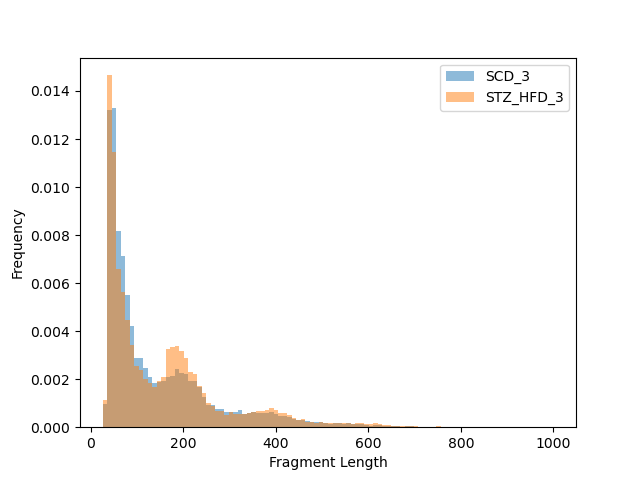

In [16]:
# --maxFragmentLength 1000: plot fragments up to 1 kb; --histogram: write the plot; the table (stdout) has the summary statistics
bamPEFragmentSize -p $THREADS -b SCD_3.filtered.bam STZ_HFD_3.filtered.bam --samplesLabel $SAMPLES \
    --maxFragmentLength 1000 --binSize 1000 --distanceBetweenBins 10000 --histogram fragment_sizes.png > fragment_sizes.txt 2> /dev/null
cat fragment_sizes.png | display
cut -f1-6 fragment_sizes.txt | column -t

### 6c. Coverage tracks

To check signal at TSSs, and later to look at the data in a genome browser, we need coverage tracks. A BAM file is too large and detailed to compare samples in a browser. A **bigWig** file stores the coverage (number of fragments overlapping each bin) and can be **normalised** so that samples with different sequencing depths become comparable.

We use deepTools `bamCoverage` with:

- `--extendReads`: count the whole fragment (from the paired reads), not just the reads.
- `--normalizeUsing RPGC` (reads per genomic content): scale coverage to 1× sequencing depth. This needs the *effective genome size*, the part of the genome reads can map to. Our reads only cover chr19, so we use the number of non-N bases of chr19.
- `--binSize 10`: the resolution of the track.

In [17]:
# effective genome size: non-N bases of chr19
GSIZE=$(samtools faidx $GENOME/mm10.fa chr19 | grep -v '>' | tr -d 'Nn\n' | wc -c)
echo "chr19 effective size: $GSIZE bp"

for s in $SAMPLES; do
    bamCoverage -p $THREADS -b ${s}.filtered.bam -o ${s}.bw --region chr19 \
        --extendReads --normalizeUsing RPGC --effectiveGenomeSize $GSIZE --binSize 10 2> /dev/null
done
ls -lh *.bw

chr19 effective size: 58205856 bp
-rw-r--r-- 1 nicolo.casonato sg_c20_pi_stein_aerts 3.9M Oct 28 11:07 SCD_3.bw
-rw-r--r-- 1 nicolo.casonato sg_c20_pi_stein_aerts 4.1M Oct 28 11:07 STZ_HFD_3.bw


### 6d. TSS enrichment

With the bigWig files we can check the second ATAC hallmark: signal around transcription start sites. `computeMatrix` collects the coverage in a ±2 kb window around every chr19 TSS, and `plotProfile` averages it. The **TSS enrichment score** is the signal at the TSS divided by the signal at the flanks. Exact values depend on how a tool computes it (window sizes, TSS annotation); as a rule of thumb ENCODE flags mouse samples below 10 as concerning and considers values above 15 ideal.

718 protein-coding TSSs on chr19


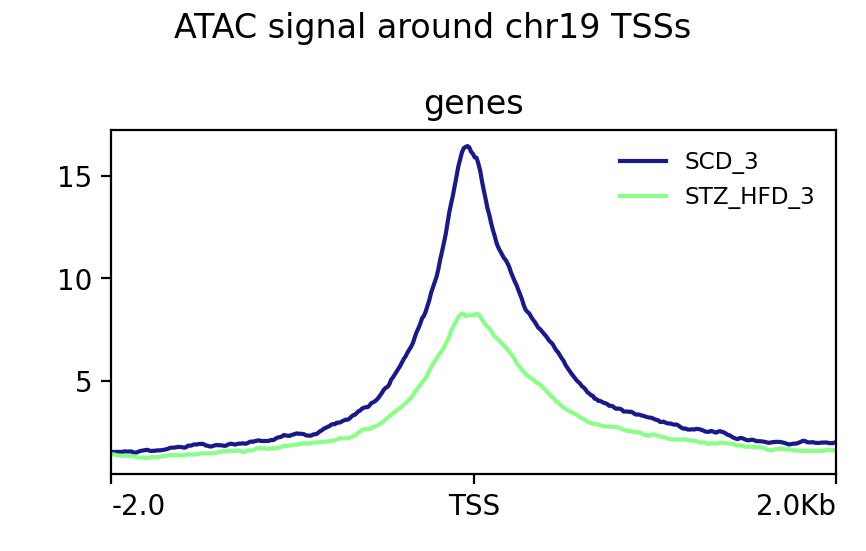

In [18]:
awk '$1 == "chr19"' $GENOME/mm10_tss_protein_coding.bed > tss_chr19.bed
echo "$(wc -l < tss_chr19.bed) protein-coding TSSs on chr19"

# reference-point: windows centred on one position per region (the TSS), 2 kb before (-b) and after (-a), in 10 bp bins
# --outFileNameMatrix: also write the matrix as text, so we can compute the enrichment score ourselves
# plotProfile --perGroup: one plot with both samples
computeMatrix reference-point -p $THREADS --referencePoint center -a 2000 -b 2000 --binSize 10 \
    -S SCD_3.bw STZ_HFD_3.bw --samplesLabel $SAMPLES -R tss_chr19.bed \
    -o tss_matrix.gz --outFileNameMatrix tss_matrix.tab 2> /dev/null
plotProfile -m tss_matrix.gz -o tss_profile.png --perGroup --refPointLabel TSS \
    --plotTitle "ATAC signal around chr19 TSSs" 2> /dev/null
cat tss_profile.png | display

Let's compute the score from the matrix: the mean signal in the central 100 bp divided by the mean signal in the outer 100 bp on both sides (the matrix has 400 bins of 10 bp per sample).

In [19]:
i=0
for s in $SAMPLES; do
    grep -v '^#' tss_matrix.tab | awk -v off=$(( i * 400 )) -v s=$s '
        NR > 1 { for (b = 1; b <= 400; b++) { v = $(off + b); if (v != "nan") { sum[b] += v } } }
        END { for (b = 196; b <= 205; b++) c += sum[b]
              for (b = 1; b <= 10; b++)    f += sum[b] + sum[400 - b + 1]
              printf "%s: TSS enrichment %.1f\n", s, (c / 10) / (f / 20) }'
    i=$(( i + 1 ))
done

SCD_3: TSS enrichment 9.0
STZ_HFD_3: TSS enrichment 5.5


You should get about 9.0 for SCD_3 and 5.5 for STZ_HFD_3. Both profiles have a clear peak at the TSS, so the libraries work, but both values are below ENCODE's threshold of 10, STZ_HFD_3 clearly so: the signal-to-noise of these libraries is modest, and differs between the two mice. ATAC-seq on frozen tissue usually gives lower values than on cultured cells, and this is a typical situation with public data. It does not make the data useless, but it is something to keep in mind for the rest of the analysis.

Tools like [ataqv](https://github.com/ParkerLab/ataqv) compute these metrics (and more) in one go. Here is a genome-wide summary for all 12 samples, computed on the full data: read numbers from fastp, bowtie2 and Picard, the chrM fraction from `samtools idxstats`, the TSS enrichment from ataqv, and peaks and FRiP from MACS3 (Step 7):

In [20]:
column -t $BULK/data_generated/qc_summary.tsv

sample     read_pairs_M  kept_after_trim_%  aligned_%  duplicates_%  chrM_%  filtered_fragments_M  TSS_enrichment  peaks  FRiP
SCD_1      44.0          98.4               98.83      20.4          8.5     27.9                  4.8             26145  0.08
SCD_2      44.2          98.1               99.30      22.4          11.1    27.3                  4.6             23713  0.08
SCD_3      35.8          98.5               99.21      19.4          8.9     23.2                  5.3             32477  0.12
STZ_SCD_1  43.8          98.1               99.42      18.3          5.6     29.0                  4.1             23555  0.08
STZ_SCD_2  43.7          98.4               99.33      21.5          10.0    27.6                  3.9             21586  0.07
STZ_SCD_3  43.9          98.1               99.46      18.7          7.4     28.6                  3.9             16926  0.06
HFD_1      43.9          97.8               99.38      19.5          6.7     28.3                  3.4         

ataqv computes the TSS enrichment in its own way, so its values (about 3.4-5.3) are not directly comparable with ours or with the ENCODE thresholds; compare samples **with each other** using one tool. Alignment, duplication (17-22%) and chrM fraction (4.6-11.5%) are fine for all samples; the weak points are the TSS enrichment and the FRiP (0.04-0.12, below ENCODE's 0.2). SCD_3, one of our two mice, has the most peaks and the highest FRiP of the 12; STZ_HFD_1 has the fewest fragments, the fewest peaks and the lowest FRiP: a sample to watch in the differential analysis.

## Step 7: Peak calling (MACS3)

Peaks are regions with significantly more fragments than expected from the local background. We use [MACS3](https://macs3-project.github.io/MACS/) `callpeak` in **paired-end mode** (`-f BAMPE`): MACS3 then uses the real fragments defined by each read pair, so there is no need to model or guess a fragment size. Unlike ChIP-seq, ATAC-seq has no input control: MACS3 estimates the local background from the sample itself (the [ChIP-seq practical](../chip-seq/index.md) calls peaks against an Input sample).

*You may have seen ATAC-seq peak calling with options like `--nomodel --shift -100 --extsize 200`. That trick is for single-end data (or for calling peaks on Tn5 cut sites only): it builds an artificial fragment around each read end. With paired-end data, `-f BAMPE` is the simpler and more accurate choice.*

Other options:

- `-g`: the effective genome size, used to compute the genome-wide background. Our reads only cover chr19, so we use the chr19 size from above.
- `--keep-dup all`: duplicates have already been removed, don't let MACS3 filter again.
- `-q 0.01`: report peaks with a false discovery rate (q-value) below 1%.

In [21]:
mkdir -p macs3
for s in $SAMPLES; do
    # -n: prefix of the output files; 2> macs3/$s.log: keep the log (it contains the fragment numbers)
    macs3 callpeak -f BAMPE -t ${s}.filtered.bam -n $s -g $GSIZE --keep-dup all -q 0.01 \
        --outdir macs3 2> macs3/${s}.log
done
wc -l macs3/*_peaks.narrowPeak

  900 macs3/SCD_3_peaks.narrowPeak
  389 macs3/STZ_HFD_3_peaks.narrowPeak
 1289 total


You should get about 900 peaks for SCD_3 and 390 for STZ_HFD_3 on chr19. Genome-wide, the same settings give about 32,000 and 21,000 peaks (see the summary table above). With a lower signal-to-noise, fewer regions rise significantly above the background, so the weaker library gets far fewer peaks, although both samples have almost the same number of fragments.

The `narrowPeak` format is a BED file with extra columns: name, score, strand, fold enrichment, -log10 p-value, -log10 q-value, and the position of the summit relative to the peak start. MACS3 also writes the summits separately (`_summits.bed`), which we will use in [part 2](part_2_consensus_peaks_macs_diff.ipynb).

In [22]:
# the 5 most significant peaks: sort on column 9 (-log10 q-value), g = general numeric, r = reverse
sort -k9,9gr macs3/SCD_3_peaks.narrowPeak | head -5
# peak width distribution
awk '{print $3 - $2}' macs3/SCD_3_peaks.narrowPeak | sort -n \
    | awk '{w[NR] = $1} END {printf "peak width: min %d, median %d, max %d bp\n", w[1], w[int(NR/2)], w[NR]}'

chr19	18712830	18713653	SCD_3_peak_305	473	.	11.8375	55.1261	47.3384	276
chr19	36409356	36410213	SCD_3_peak_557	455	.	11.4032	52.5182	45.5757	410
chr19	24961348	24961918	SCD_3_peak_392	454	.	12.8365	52.3742	45.4896	374
chr19	14598028	14598941	SCD_3_peak_262	448	.	8.8626	51.6181	44.8558	213
chr19	18670583	18671379	SCD_3_peak_304	448	.	10.988	51.2751	44.8558	214
peak width: min 140, median 350, max 1918 bp


### Fraction of reads in peaks (FRiP)

FRiP is the fraction of all fragments that fall in peaks: a measure of signal-to-noise. ENCODE asks for FRiP > 0.2 (ideally > 0.3) for ATAC-seq; for transcription factor ChIP-seq, where peaks are fewer and narrower, 1% is already acceptable (see the [ChIP-seq practical](../chip-seq/index.md)). Let's compute it for both samples: we count all fragments, and the fragments whose first read overlaps a peak. (Counting only the first read slightly underestimates FRiP, as a fragment whose second read lies in a peak is missed, but it is simple and the same for both samples.)

In [23]:
for s in $SAMPLES; do
    # -c: only count; -f 64: only the first read of each pair, so we count fragments
    total=$(samtools view -c -f 64 ${s}.filtered.bam)
    # -L: only reads overlapping the regions of a BED file (here: the peaks); with -f 64, fragments whose first read is in a peak
    in_peaks=$(samtools view -c -f 64 -L macs3/${s}_peaks.narrowPeak ${s}.filtered.bam)
    awk -v s=$s -v p=$in_peaks -v t=$total 'BEGIN {printf "%s: %d of %d fragments in peaks, FRiP = %.2f\n", s, p, t, p/t}'
done

SCD_3: 57059 of 448687 fragments in peaks, FRiP = 0.13
STZ_HFD_3: 20308 of 460395 fragments in peaks, FRiP = 0.04


FRiP is 0.13 for SCD_3 and only 0.04 for STZ_HFD_3 on chr19, with each sample's own peaks: both below ENCODE's 0.2, and very different between the two mice.

FRiP depends on the peak set: with fewer peaks, fewer fragments fall in peaks. That is why [part 2](part_2_consensus_peaks_macs_diff.ipynb) computes FRiP again for all samples on one common set of regions.

## Step 8: Looking at the data

### In IGV

Download the two bigWig files (`*.bw`) and the two peak files (`macs3/*_peaks.narrowPeak`) and load them in [IGV](https://igv.org/app/) with genome **mm10**. Select both bigWig tracks, right-click and choose *Group Autoscale* so they share the same y-axis.

chr19 holds several genes that matter in a liver under diabetes and a high-fat diet:

| gene | role |
|---|---|
| *Scd1* | stearoyl-CoA desaturase, lipogenesis (induced by insulin and by dietary fat) |
| *Cpt1a* | carnitine palmitoyltransferase, rate-limiting for fatty-acid oxidation |
| *Fads1*, *Fads2* | fatty-acid desaturases |
| *Rbp4* | retinol-binding protein, secreted by hepatocytes |
| *Pten* | ubiquitously expressed phosphatase: a useful "unchanged" control |

Browse to each gene. Where are the peaks: at the promoter, in introns, between genes? Do the two samples look different?

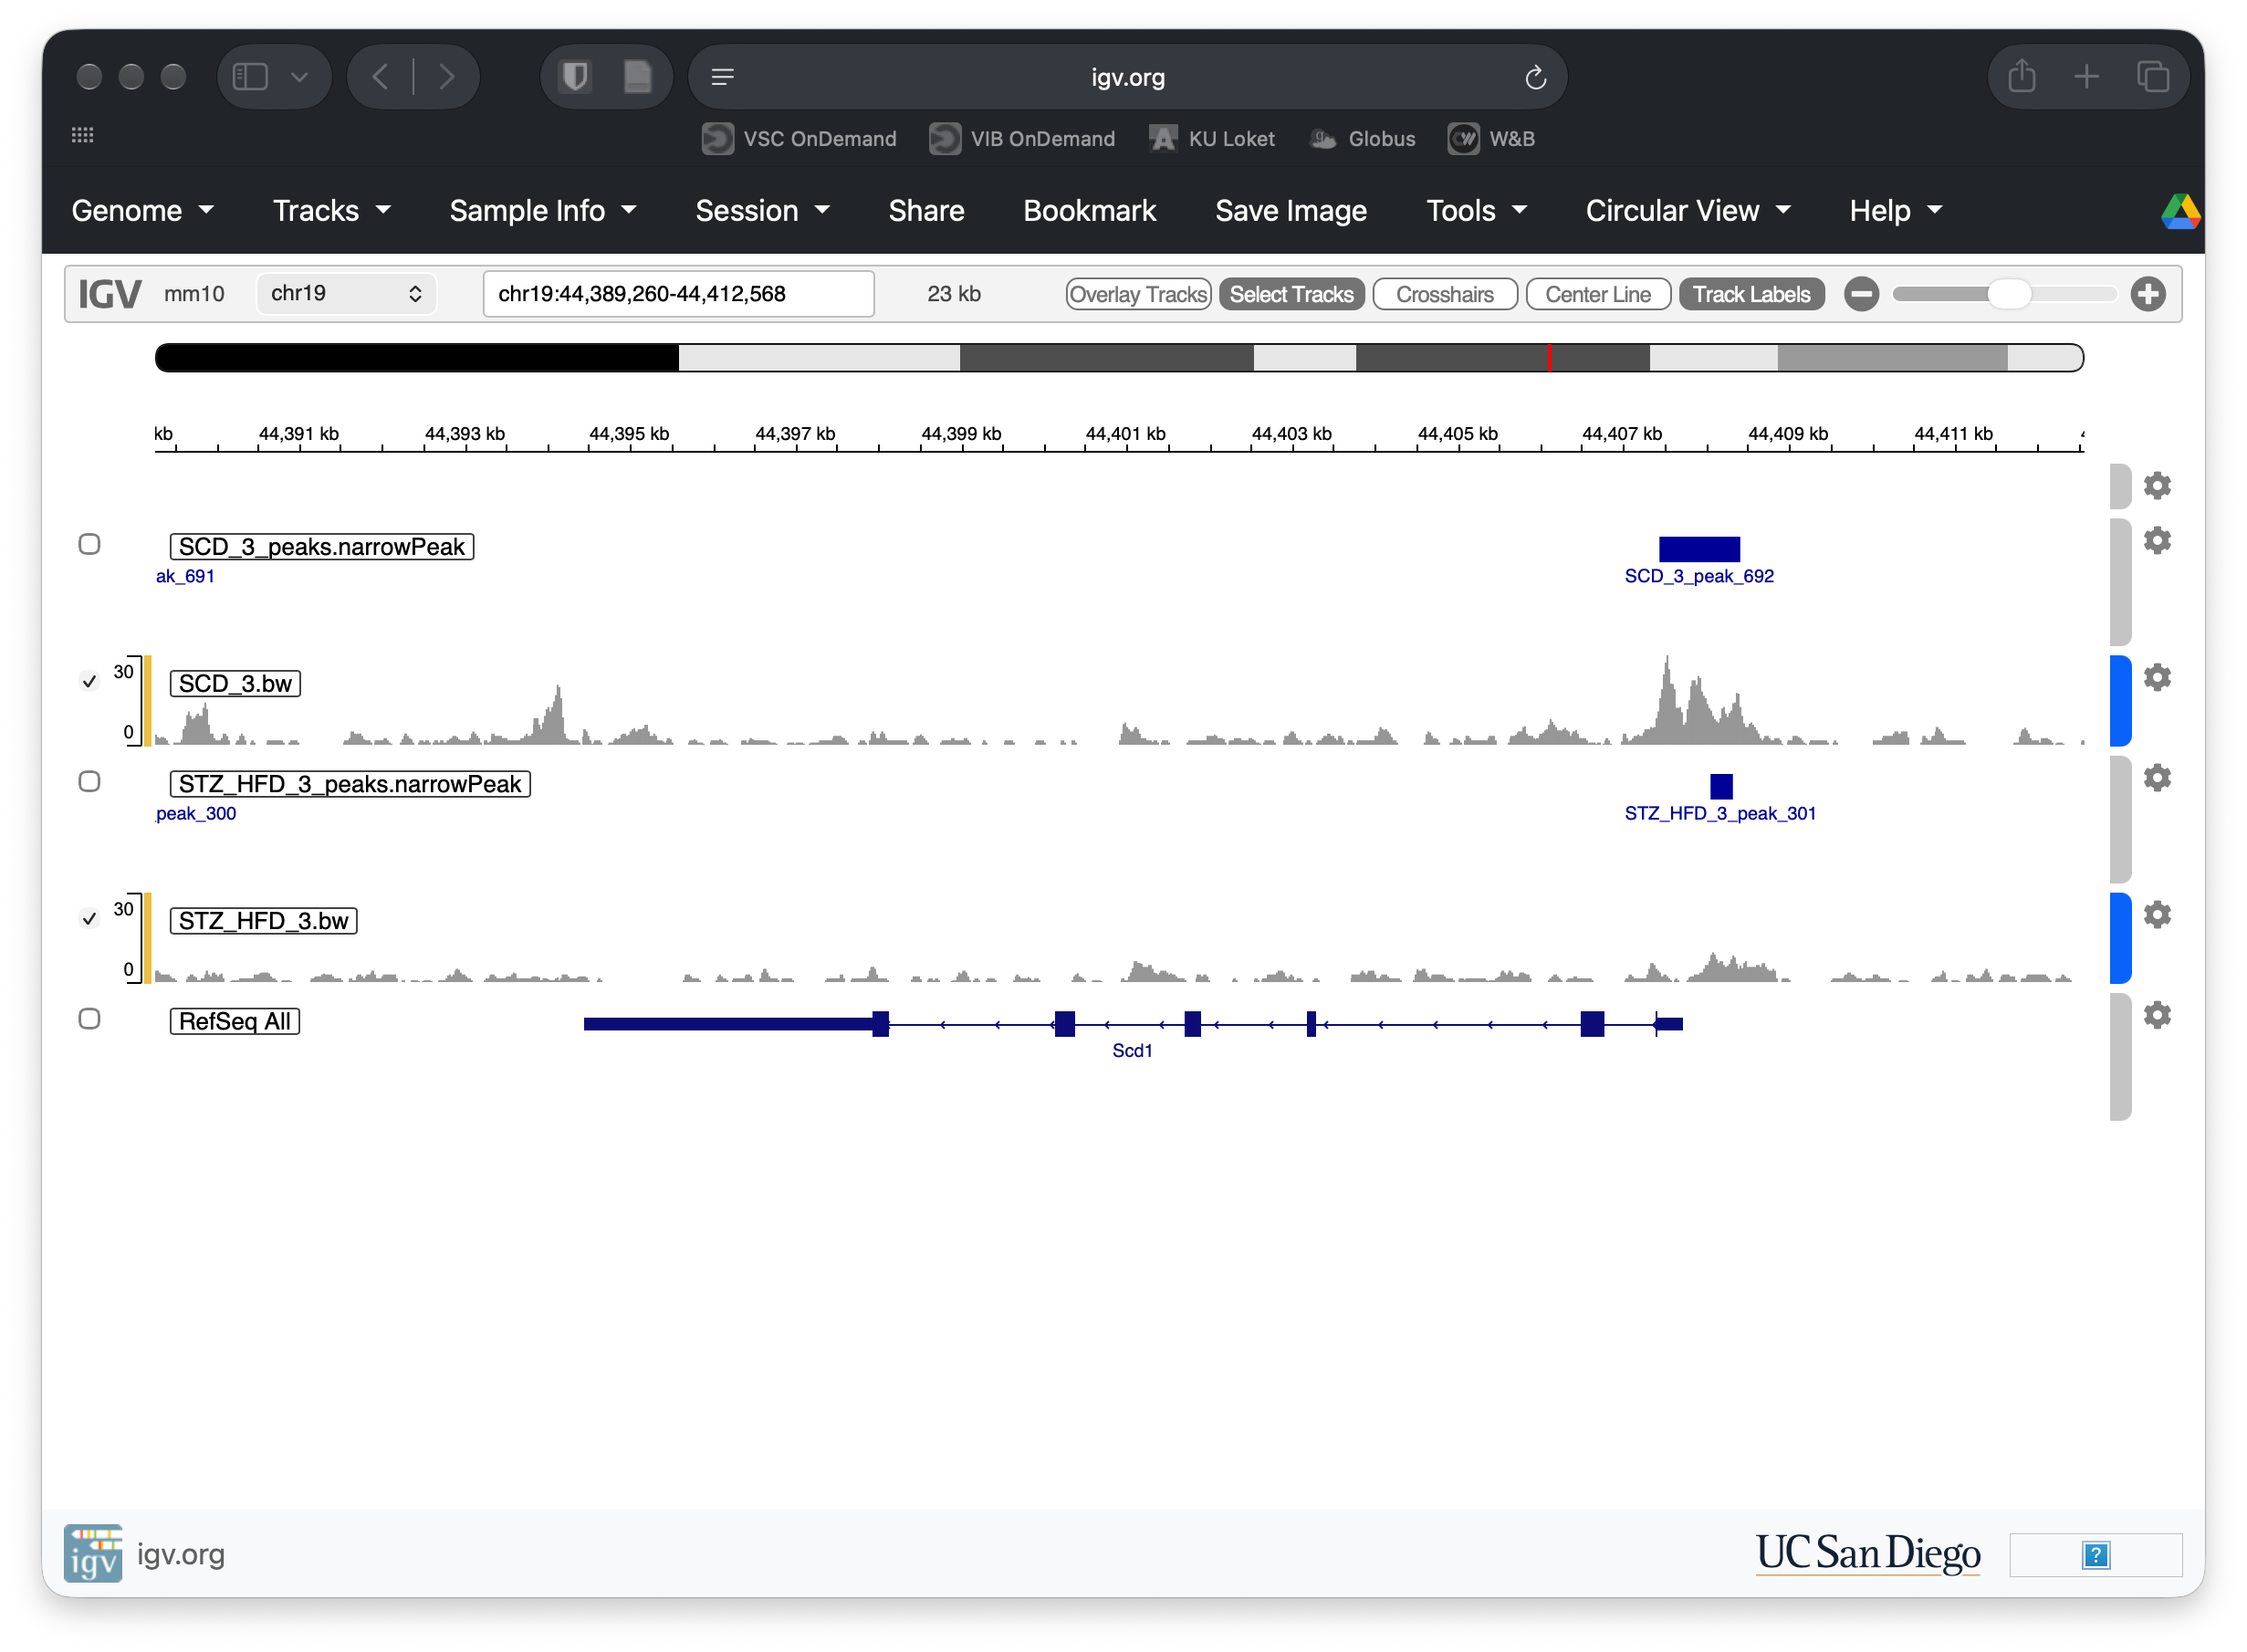

*Scd1* in IGV, with both coverage tracks on the same scale (*Group Autoscale*). *Scd1* lies on the minus strand, so its promoter is on the right. In SCD_3 the promoter is a clear, broad peak (about 1 kb); in STZ_HFD_3 the signal there is much lower and MACS3 calls only a short peak. The background between the peaks is similar in both mice, so in STZ_HFD_3 the promoter stands out much less from the noise: the lower signal-to-noise we measured with TSS enrichment and FRiP.

### In numbers

We can also quantify the signal at the promoters of these genes. First, build a BED file with a window of ±1 kb around each TSS:

In [24]:
# grep -w: match whole words only (no partial matches inside longer gene names); awk: extend each TSS by 1 kb on both sides
grep -wE 'Scd1|Cpt1a|Fads1|Fads2|Rbp4|Pten' tss_chr19.bed \
    | awk 'BEGIN {OFS = "\t"} {print $1, $2 - 1000, $3 + 1000, $4}' > promoters.bed
cat promoters.bed

chr19	3321333	3323334	Cpt1a
chr19	10100745	10102746	Fads2
chr19	10181887	10183888	Fads1
chr19	32756496	32758497	Pten
chr19	38124280	38126281	Rbp4
chr19	44406878	44408879	Scd1


`multiBigwigSummary` computes the mean normalised coverage of each bigWig in each region:

In [25]:
# BED-file mode: one value per region of promoters.bed; --outRawCounts: write the values as a table
multiBigwigSummary BED-file -b SCD_3.bw STZ_HFD_3.bw --labels $SAMPLES --BED promoters.bed \
    -o promoters.npz --outRawCounts promoters_signal.tab 2> /dev/null
# add gene names and the STZ_HFD / SCD ratio
sort -k1,1 -k2,2n promoters.bed > promoters.sorted.bed
echo -e "gene\tSCD_3\tSTZ_HFD_3\tratio"
grep -v '^#' promoters_signal.tab | sort -k1,1 -k2,2n | paste - promoters.sorted.bed \
    | awk 'BEGIN {OFS = "\t"} {printf "%s\t%.2f\t%.2f\t%.2f\n", $9, $4, $5, $5 / $4}'

gene	SCD_3	STZ_HFD_3	ratio
Cpt1a	8.64	5.46	0.63
Fads2	15.47	5.13	0.33
Fads1	13.95	5.93	0.42
Pten	21.11	14.72	0.70
Rbp4	9.34	3.92	0.42
Scd1	9.66	3.72	0.38


All six promoters look less accessible in the STZ + HFD mouse, *Scd1* and *Fads2* even about three times less. Can we conclude that the treatment changes their accessibility?

No. We compared **one mouse with one other mouse**. Two mice from the *same* group also differ (biological variation: liver state, feeding time, sampling), and the library preparation adds technical variation. Without replicates we cannot tell whether a difference is larger than the normal mouse-to-mouse variation. In addition, a ratio of normalised coverage gives no measure of uncertainty: a region with very few fragments can show a large ratio by chance.

Look at *Pten*, our "unchanged" control: it also drops, by about 30%. When **every** region goes down, at least part of the cause is technical: STZ_HFD_3 has a lower signal-to-noise (TSS enrichment 5.5 vs 9.0, FRiP 0.04 vs 0.13), so less of its signal is in accessible regions. RPGC normalisation corrects for sequencing depth, not for library quality. The lipogenic genes drop more than *Pten*, which is suggestive, but with one mouse per group we cannot separate a real effect from library quality and mouse-to-mouse variation.

That is why the experiment has **three mice per group**, and why the next notebooks:

- build one common set of regions (**consensus peaks**) for all 12 samples and count fragments in them, then try MACS3's differential mode ([part 2](part_2_consensus_peaks_macs_diff.ipynb));
- test for differences with statistical models that use the replicates, **DiffBind** and **DESeq2** ([part 3](part_3_diffbind_deseq2.ipynb)).

## Summary

| step | tool | output |
|---|---|---|
| read QC | FastQC | HTML reports |
| trimming | fastp | `*_trimmed_R?.fastq.gz` |
| alignment | bowtie2 + samtools | `*.sorted.bam` |
| duplicates | Picard MarkDuplicates | `*.markdup.bam` |
| filtering | samtools + bedtools | `*.filtered.bam` |
| ATAC QC | deepTools, samtools | fragment sizes, TSS enrichment, chrM fraction |
| coverage | deepTools bamCoverage | `*.bw` |
| peaks | MACS3 (BAMPE) | `macs3/*_peaks.narrowPeak`, FRiP |

The genome-wide versions of all these files, for all 12 samples, are in `data/data_generated/`. [Part 2](part_2_consensus_peaks_macs_diff.ipynb) starts from there.

## Exercises

1. For `SCD_3`, how many reads does each filter of Step 5 remove on its own? Use `samtools view -c` (count) on `SCD_3.markdup.bam` with one filter at a time (`-f 2`, `-f 1024`, `-q 30`, the chromosome `chrM`, and `-L` with the blacklist). Which filter removes the most reads?
2. How many R1 reads of `SCD_3` contain the Nextera/Tn5 adapter? (Hint: the adapter starts with `CTGTCTCTTATA`; `awk 'NR % 4 == 2'` prints only the sequence lines of a FASTQ file, and `grep -c` counts matching lines.) How does this compare with the "Adapter Content" plot of FastQC and with the number of reads fastp trimmed?
3. Repeat the promoter quantification of Step 8 for a few other chr19 genes of your choice (`tss_chr19.bed` lists them all). How many promoters are lower in STZ_HFD_3, and by how much? What does this tell you about the drop of *Pten*?